# **SmartCropAdvisor: Data Preparation and Exploratory Analysis**

Author: `Rozhak`  
Version: 1.1.0  
Tujuan: *Memvalidasi integritas dataset tanah dan iklim serta menyusun visualisasi Exploratory Data Analysis (EDA) sebagai acuan tahap pemodelan dan Streamlit UI.*

## **1. Pendahuluan**

Notebook ini berfokus pada validasi data dan Exploratory Data Analysis (EDA) sebelum tahap pemodelan. Seluruh path file, daftar fitur, dan batas nilai validasi dibaca dari `../config/settings.yaml`.

## **2. Konfigurasi dan Logging**

Memuat konfigurasi YAML ke `DataConfig` dan menyiapkan fungsi `log_event` berformat key-value untuk mencatat setiap tahapan proses.

In [1]:
from dataclasses import dataclass
from pathlib import Path
from typing import Any

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import yaml

from IPython.display import display


def log_event(category: str, **kwargs: Any) -> None:
    details = " | ".join(f"{k}={v}" for k, v in kwargs.items())
    print(f"[{category.upper()}] {details}")


@dataclass(frozen=True)
class DataConfig:
    base_dir: Path
    raw_path: Path
    plots_dir: Path
    target_column: str
    feature_columns: list[str]
    min_samples_per_class: int
    domain_bounds: dict[str, tuple[float, float]]


def load_config(config_path: Path) -> DataConfig:
    if not config_path.exists():
        raise FileNotFoundError(f"Config file not found: {config_path}")

    with config_path.open("r", encoding="utf-8") as file:
        raw = yaml.safe_load(file)

    base_dir = config_path.parent.parent
    plots_dir = base_dir / raw["artifacts"]["eda_plots_dir"]
    plots_dir.mkdir(parents=True, exist_ok=True)

    bounds = {
        k: (float(v[0]), float(v[1]))
        for k, v in raw["data"].get("domain_bounds", {}).items()
    }

    cfg = DataConfig(
        base_dir=base_dir,
        raw_path=base_dir / raw["data"]["raw_path"],
        plots_dir=plots_dir,
        target_column=raw["data"]["target_column"],
        feature_columns=list(raw["data"]["feature_columns"]),
        min_samples_per_class=int(raw["data"].get("min_samples_per_class", 5)),
        domain_bounds=bounds,
    )
    log_event(
        "CONFIG",
        status="LOADED",
        dataset=cfg.raw_path.name,
        features=len(cfg.feature_columns),
        plots_dir=cfg.plots_dir.as_posix(),
    )
    return cfg


config = load_config(Path("../config/settings.yaml"))

[CONFIG] status=LOADED | dataset=soil_quality_crop_recommendation_dataset.csv | features=7 | plots_dir=../artifacts/plots/eda


## **3. Pemuatan dan Validasi Data**

Memuat dataset mentah serta memvalidasi skema kolom, tipe numerik, nilai `NaN`/`Inf`, batas fisik fitur, dan jumlah sampel minimal per kelas.

### **3.1 Validasi Skema dan Kualitas Data**

Pemeriksaan skema kolom dan rentang nilai dilakukan di awal agar ketidaksesuaian skema atau kelas dengan sampel kurang dari batas `StratifiedKFold` langsung terdeteksi sebelum analisis berlanjut.

In [2]:
@dataclass(frozen=True)
class ValidationReport:
    rows: int
    cols: int
    missing_values: int
    duplicate_rows: int
    num_classes: int
    min_class_count: int


def load_and_validate_data(cfg: DataConfig) -> tuple[pd.DataFrame, ValidationReport]:
    log_event("DATA_LOAD", status="STARTED", path=cfg.raw_path.as_posix())
    if not cfg.raw_path.exists():
        log_event("DATA_LOAD", status="FAILED", reason="FILE_NOT_FOUND")
        raise FileNotFoundError(f"Dataset not found: {cfg.raw_path}")

    df = pd.read_csv(cfg.raw_path)
    expected_cols = set(cfg.feature_columns + [cfg.target_column])
    missing_cols = expected_cols - set(df.columns)
    if missing_cols:
        log_event("SCHEMA_CHECK", status="FAILED", missing_cols=sorted(missing_cols))
        raise ValueError(f"Missing required columns: {sorted(missing_cols)}")

    for col in cfg.feature_columns:
        if not pd.api.types.is_numeric_dtype(df[col]):
            log_event("SCHEMA_CHECK", status="FAILED", non_numeric_column=col)
            raise TypeError(f"Feature column must be numeric: {col}")
        if not np.isfinite(df[col]).all():
            log_event("DATA_QUALITY", status="FAILED", non_finite_column=col)
            raise ValueError(f"Feature column contains NaN or Inf: {col}")
        if col in cfg.domain_bounds:
            low, high = cfg.domain_bounds[col]
            out_of_bounds = int(((df[col] < low) | (df[col] > high)).sum())
            if out_of_bounds > 0:
                log_event("DOMAIN_CHECK", status="FAILED", column=col, violations=out_of_bounds)
                raise ValueError(f"Column {col} has {out_of_bounds} values outside [{low}, {high}]")

    if df[cfg.target_column].isnull().any():
        raise ValueError("Target column contains missing values")

    cleaned_labels = df[cfg.target_column].astype(str).str.strip()
    if (cleaned_labels == "").any():
        raise ValueError("Target column contains empty labels")
    df[cfg.target_column] = cleaned_labels

    missing_count = int(df.isnull().sum().sum())
    duplicate_count = int(df.duplicated().sum())
    class_counts = df[cfg.target_column].value_counts()
    num_classes = int(class_counts.shape[0])
    min_class_count = int(class_counts.min())

    if min_class_count < cfg.min_samples_per_class:
        log_event("CLASS_CHECK", status="FAILED", min_class_count=min_class_count, required=cfg.min_samples_per_class)
        raise ValueError(f"Minimum class count {min_class_count} is below {cfg.min_samples_per_class}")

    report = ValidationReport(
        rows=int(df.shape[0]),
        cols=int(df.shape[1]),
        missing_values=missing_count,
        duplicate_rows=duplicate_count,
        num_classes=num_classes,
        min_class_count=min_class_count,
    )
    log_event(
        "DATA_LOAD",
        status="SUCCESS",
        rows=report.rows,
        cols=report.cols,
        missing=report.missing_values,
        duplicates=report.duplicate_rows,
        classes=report.num_classes,
        min_class_count=report.min_class_count,
    )
    return df, report


df, validation_report = load_and_validate_data(config)

[DATA_LOAD] status=STARTED | path=../data/soil_quality_crop_recommendation_dataset.csv
[DATA_LOAD] status=SUCCESS | rows=2200 | cols=8 | missing=0 | duplicates=0 | classes=22 | min_class_count=100


### **3.2 Statistik Deskriptif dan Profil Tanaman**

Menampilkan 5 baris awal dataset, ringkasan statistik fitur numerik, serta rata-rata nilai fitur untuk masing-masing kelas tanaman.

In [3]:
display(df.head())
display(df[config.feature_columns].describe().T.round(3))

crop_profile = df.groupby(config.target_column)[config.feature_columns].mean().round(2)
log_event("SUMMARY", status="COMPUTED", crop_profiles=crop_profile.shape[0])
display(crop_profile)

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


,count,mean,std,min,25%,50%,75%,max
N,2200.0,50.552,36.917,0.000,21.000,37.000,84.250,140.000
P,2200.0,53.363,32.986,5.000,28.000,51.000,68.000,145.000
K,2200.0,48.149,50.648,5.000,20.000,32.000,49.000,205.000
temperature,2200.0,25.616,5.064,8.826,22.769,25.599,28.562,43.675
humidity,2200.0,71.482,22.264,14.258,60.262,80.473,89.949,99.982
ph,2200.0,6.469,0.774,3.505,5.972,6.425,6.924,9.935
rainfall,2200.0,103.464,54.958,20.211,64.552,94.868,124.268,298.560


[SUMMARY] status=COMPUTED | crop_profiles=22


,N,P,K,temperature,humidity,ph,rainfall
label,,,,,,,
apple,20.80,134.22,199.89,22.63,92.33,5.93,112.65
banana,100.23,82.01,50.05,27.38,80.36,5.98,104.63
blackgram,40.02,67.47,19.24,29.97,65.12,7.13,67.88
chickpea,40.09,67.79,79.92,18.87,16.86,7.34,80.06
coconut,21.98,16.93,30.59,27.41,94.84,5.98,175.69
coffee,101.20,28.74,29.94,25.54,58.87,6.79,158.07
cotton,117.77,46.24,19.56,23.99,79.84,6.91,80.40
grapes,23.18,132.53,200.11,23.85,81.88,6.03,69.61
jute,78.40,46.86,39.99,24.96,79.64,6.73,174.79


## **4. Exploratory Data Analysis (EDA)**

Menghasilkan visualisasi distribusi, korelasi, dan sebaran kelas, lalu menyimpannya ke `artifacts/plots/eda/` untuk dokumentasi dan konsumsi Streamlit UI.

### **4.1 Distribusi Fitur Numerik**

Plot histogram dan kurva KDE untuk melihat bentuk distribusi tiap fitur, apakah bersifat unimodal, multimodal, atau *skewed*.

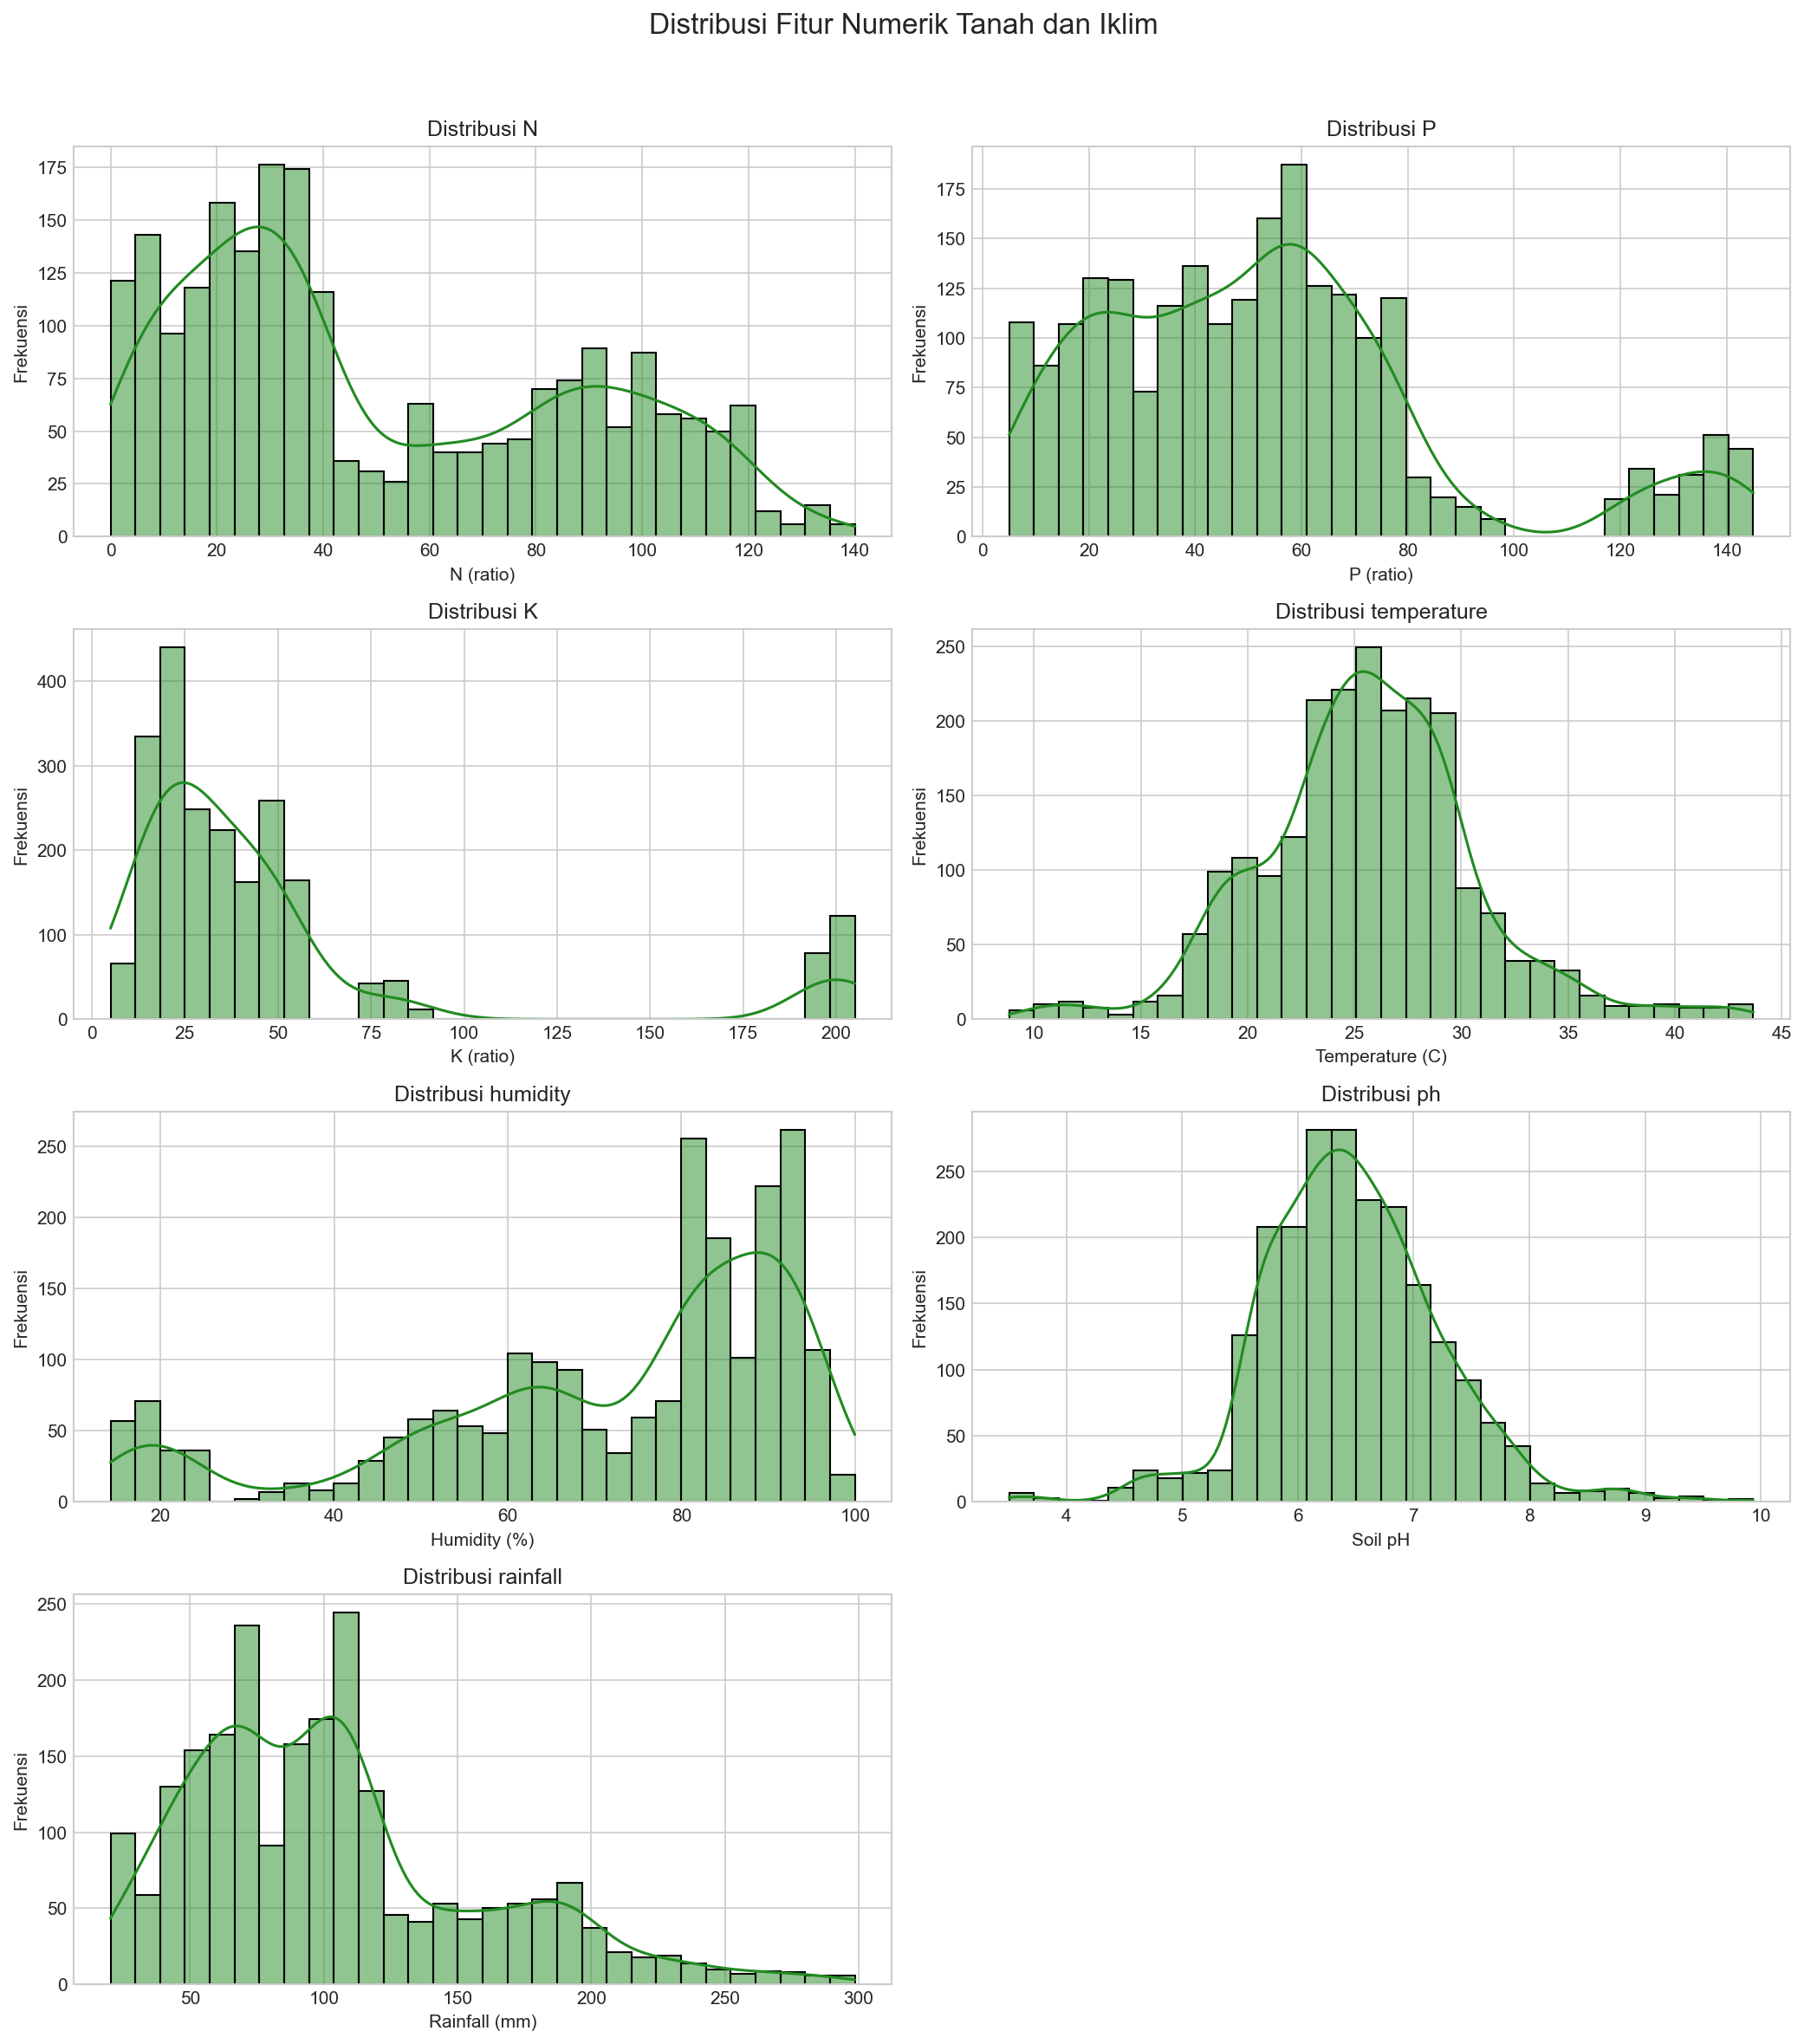

[EDA_PLOT] chart=feature_distributions | saved=../artifacts/plots/eda/eda_feature_distributions.png


In [4]:
def plot_feature_distributions(data: pd.DataFrame, cfg: DataConfig) -> Path:
    unit_labels = {
        "N": "N (ratio)",
        "P": "P (ratio)",
        "K": "K (ratio)",
        "temperature": "Temperature (C)",
        "humidity": "Humidity (%)",
        "ph": "Soil pH",
        "rainfall": "Rainfall (mm)",
    }
    features = cfg.feature_columns
    with plt.style.context("seaborn-v0_8-whitegrid"):
        fig, axes = plt.subplots(4, 2, figsize=(14, 16), dpi=150)
        fig.suptitle("Distribusi Fitur Numerik Tanah dan Iklim", fontsize=16, y=0.98)
        axes_flat = axes.flatten()

        for idx, col in enumerate(features):
            sns.histplot(data[col], kde=True, bins=30, ax=axes_flat[idx], color="forestgreen")
            axes_flat[idx].set_title(f"Distribusi {col}", fontsize=12)
            axes_flat[idx].set_xlabel(unit_labels.get(col, col))
            axes_flat[idx].set_ylabel("Frekuensi")

        for extra_idx in range(len(features), len(axes_flat)):
            fig.delaxes(axes_flat[extra_idx])

        plt.tight_layout(rect=[0, 0, 1, 0.96])
        output_path = cfg.plots_dir / "eda_feature_distributions.png"
        fig.savefig(output_path, bbox_inches="tight")
        plt.show()
    log_event("EDA_PLOT", chart="feature_distributions", saved=output_path.as_posix())
    return output_path


_ = plot_feature_distributions(df, config)

### **4.2 Korelasi Antar Fitur**

Heatmap korelasi linear antar fitur numerik untuk mendeteksi fitur yang saling berkorelasi tinggi sebelum pemodelan.

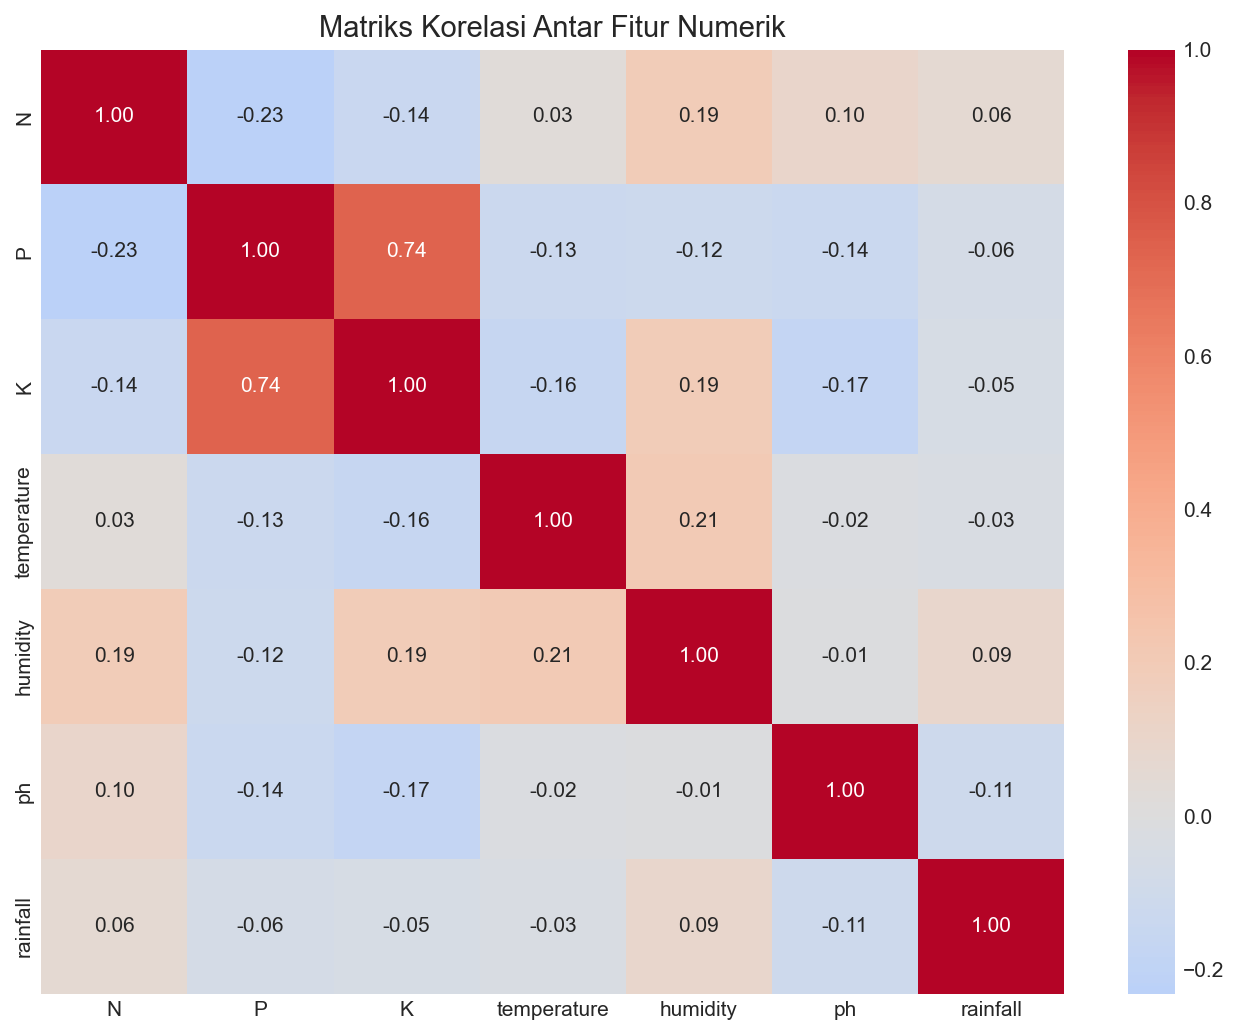

[EDA_PLOT] chart=correlation_heatmap | saved=../artifacts/plots/eda/eda_correlation_heatmap.png


In [5]:
def plot_correlation_heatmap(data: pd.DataFrame, cfg: DataConfig) -> Path:
    corr = data[cfg.feature_columns].corr()
    with plt.style.context("seaborn-v0_8-whitegrid"):
        fig, ax = plt.subplots(figsize=(9, 7), dpi=150)
        sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
        ax.set_title("Matriks Korelasi Antar Fitur Numerik", fontsize=14)
        plt.tight_layout()
        output_path = cfg.plots_dir / "eda_correlation_heatmap.png"
        fig.savefig(output_path, bbox_inches="tight")
        plt.show()
    log_event("EDA_PLOT", chart="correlation_heatmap", saved=output_path.as_posix())
    return output_path


_ = plot_correlation_heatmap(df, config)

### **4.3 Distribusi Kelas Target**

Grafik jumlah sampel per jenis tanaman untuk memastikan proporsi kelas seimbang sebelum menentukan strategi *splitting*.

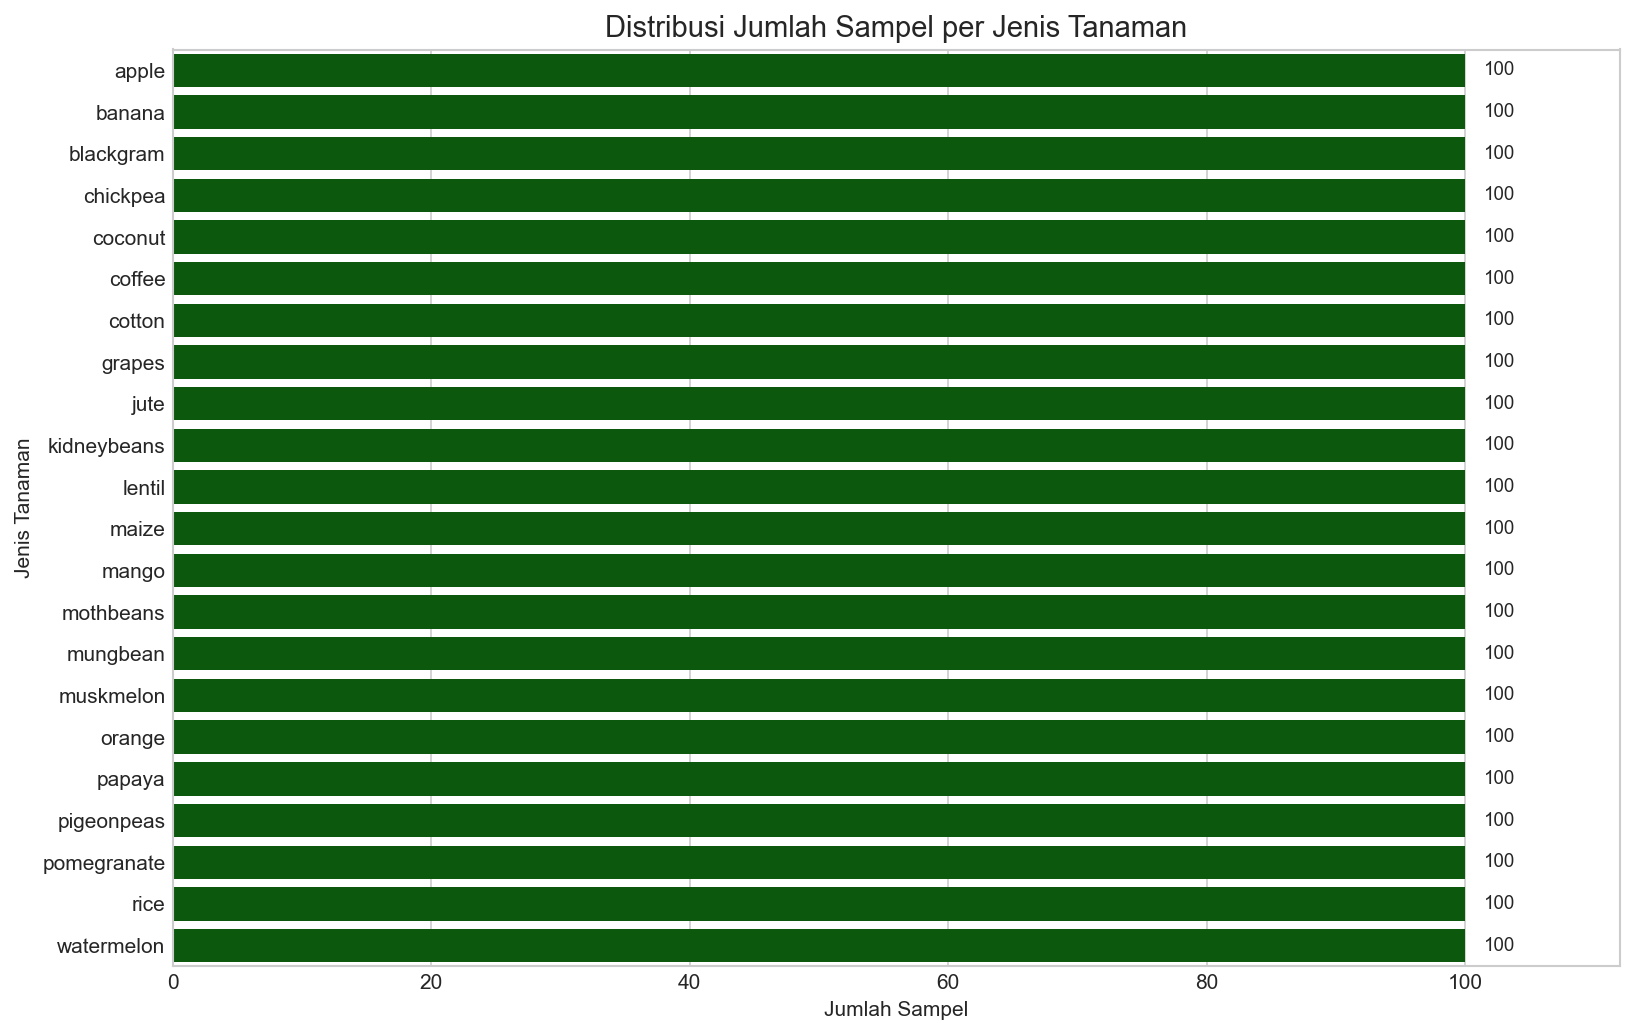

[EDA_PLOT] chart=class_distribution | saved=../artifacts/plots/eda/eda_class_distribution.png


In [6]:
def plot_class_distribution(data: pd.DataFrame, cfg: DataConfig) -> Path:
    counts = data[cfg.target_column].value_counts().sort_index()
    with plt.style.context("seaborn-v0_8-whitegrid"):
        fig, ax = plt.subplots(figsize=(11, 7), dpi=150)
        sns.barplot(y=counts.index, x=counts.values, ax=ax, color="darkgreen")
        ax.set_title("Distribusi Jumlah Sampel per Jenis Tanaman", fontsize=14)
        ax.set_xlabel("Jumlah Sampel")
        ax.set_ylabel("Jenis Tanaman")
        for patch in ax.patches:
            width = patch.get_width()
            ax.text(width + 1.5, patch.get_y() + patch.get_height() / 2, f"{int(width)}", va="center", fontsize=9)
        ax.set_xlim(0, float(counts.max()) * 1.12)
        plt.tight_layout()
        output_path = cfg.plots_dir / "eda_class_distribution.png"
        fig.savefig(output_path, bbox_inches="tight")
        plt.show()
    log_event("EDA_PLOT", chart="class_distribution", saved=output_path.as_posix())
    return output_path


_ = plot_class_distribution(df, config)

### **4.4 Sebaran Nutrisi Tanah dan pH per Tanaman**

Boxplot perbandingan rentang `N`, `P`, `K`, dan `ph` antar kelas tanaman. Grafik dikelompokkan terpisah agar label sumbu tetap mudah dibaca.

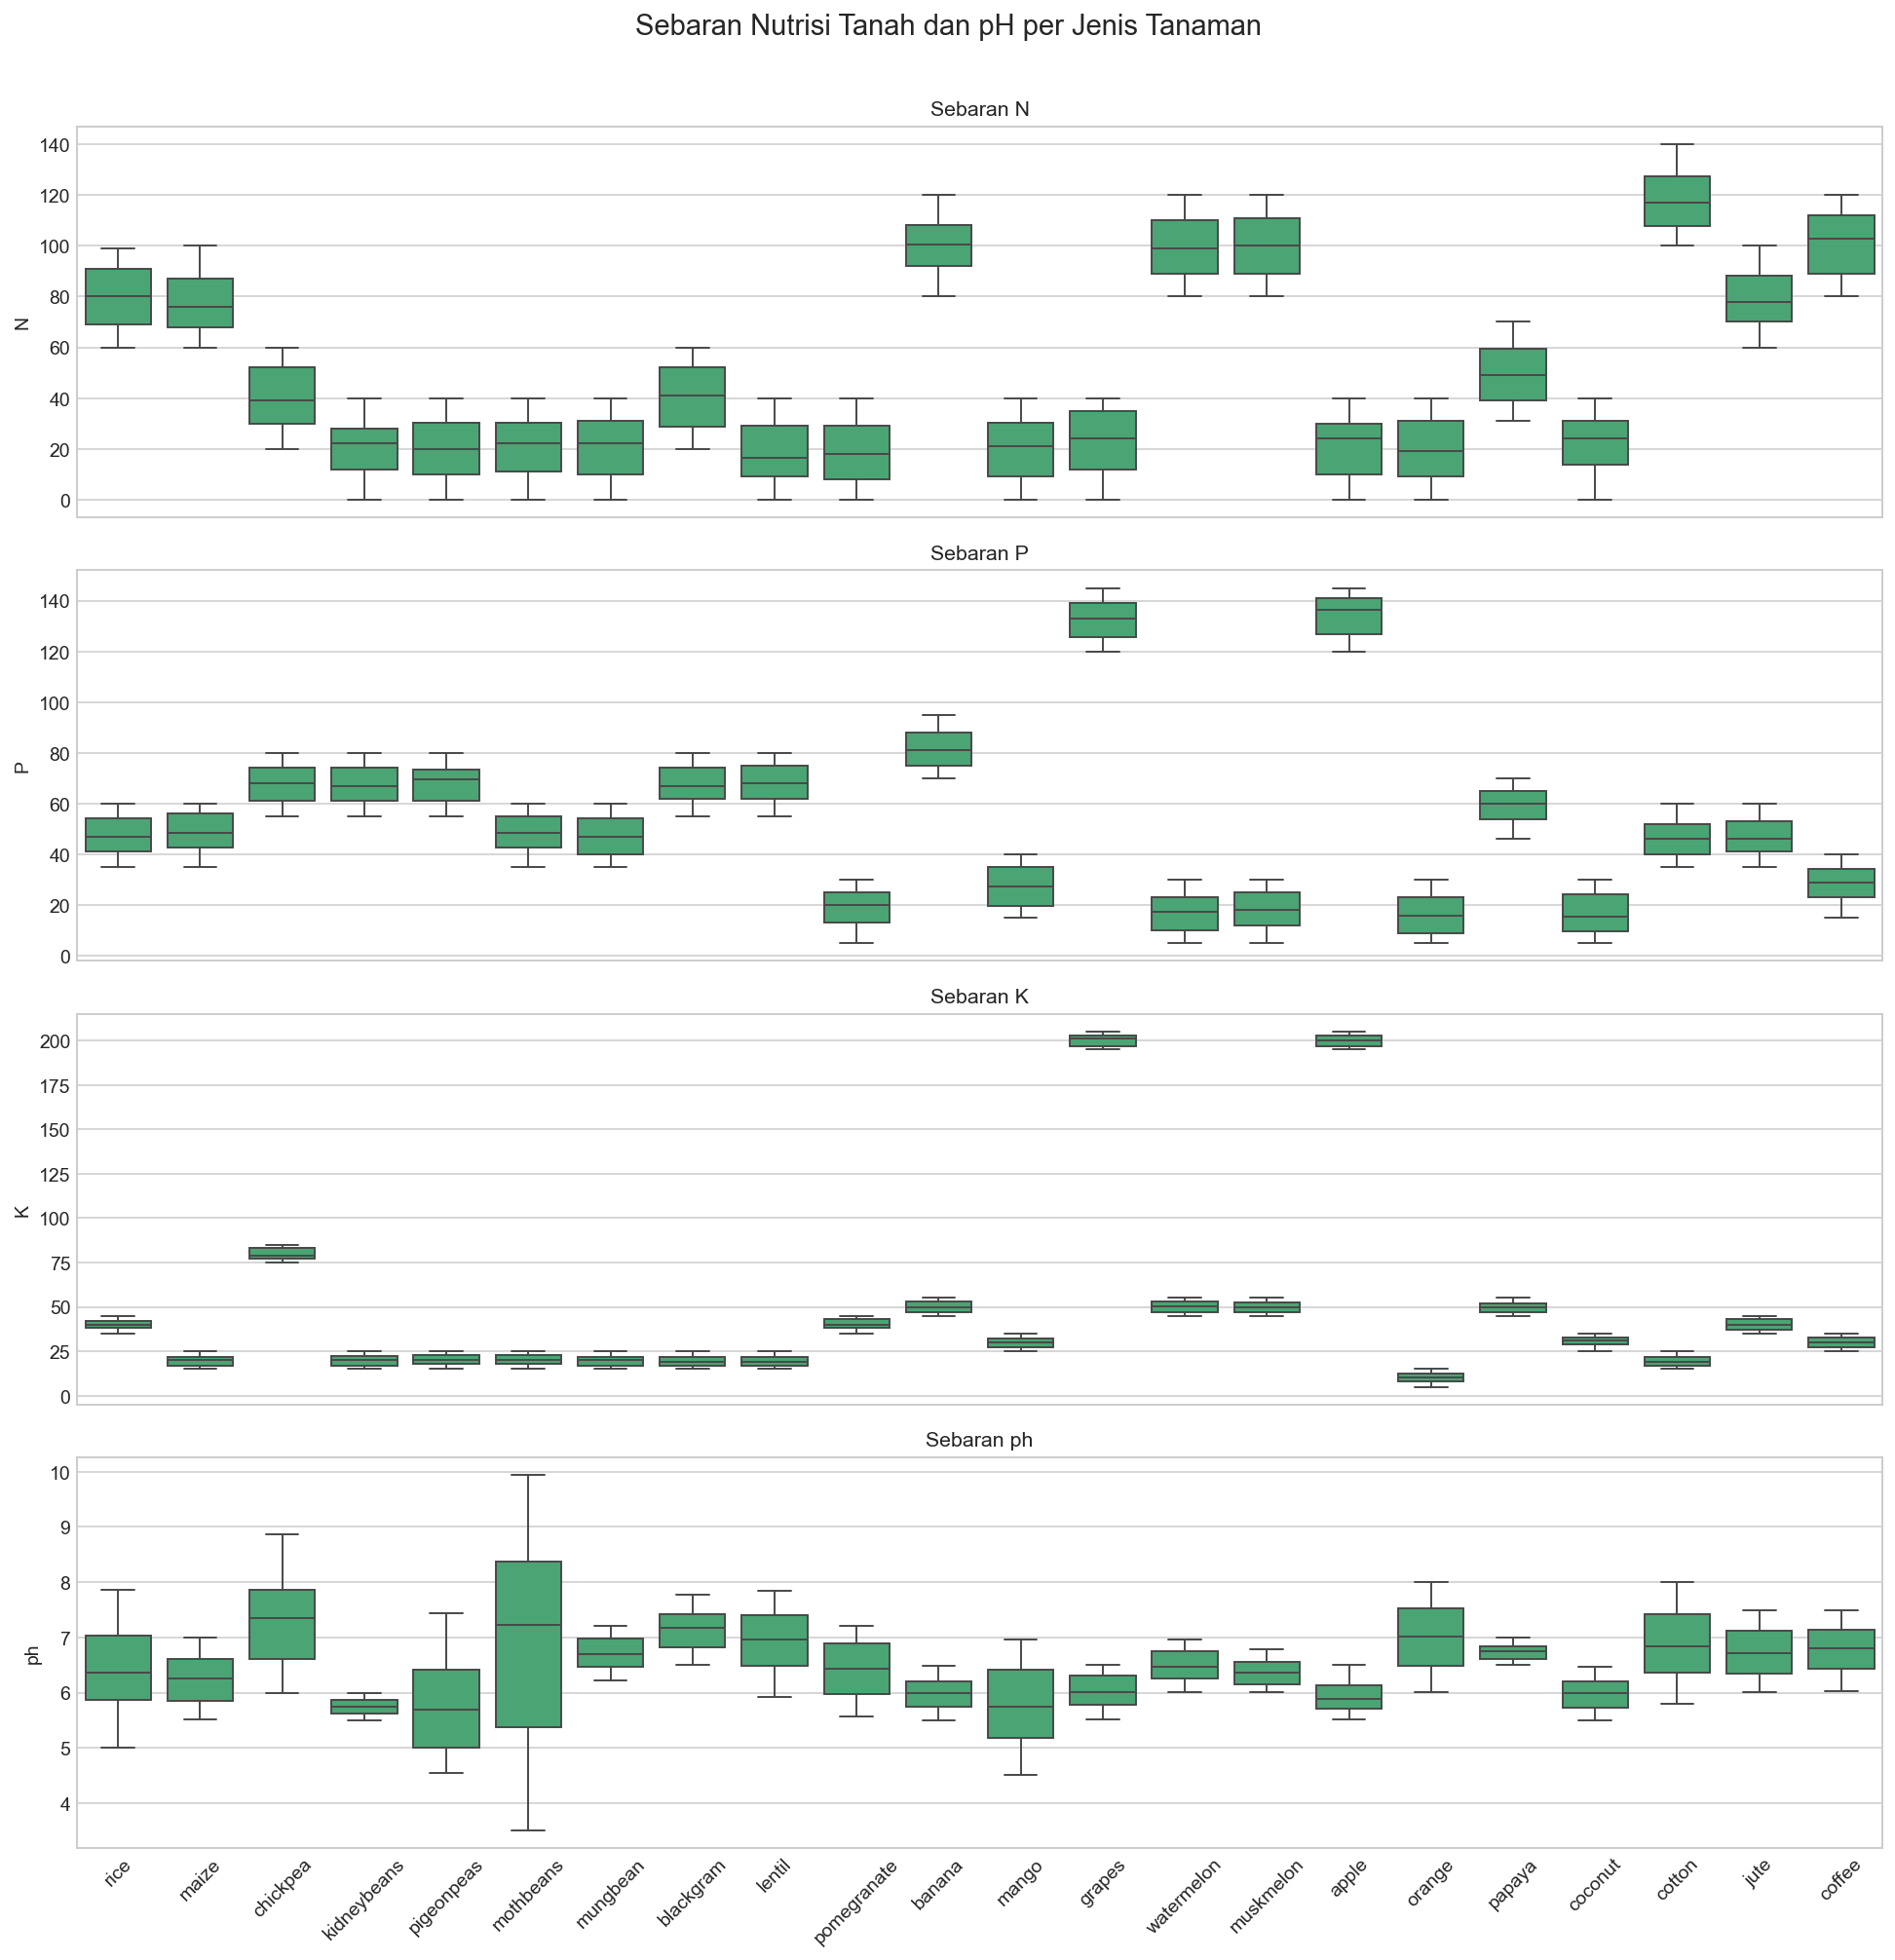

[EDA_PLOT] chart=eda_soil_boxplots.png | saved=../artifacts/plots/eda/eda_soil_boxplots.png


In [7]:
def plot_feature_group_boxplots(data: pd.DataFrame, cfg: DataConfig, features: list[str], title: str, filename: str) -> Path:
    with plt.style.context("seaborn-v0_8-whitegrid"):
        fig, axes = plt.subplots(len(features), 1, figsize=(14, 3.6 * len(features)), dpi=140, sharex=True)
        fig.suptitle(title, fontsize=15, y=0.995)

        for idx, col in enumerate(features):
            sns.boxplot(data=data, x=cfg.target_column, y=col, ax=axes[idx], color="mediumseagreen")
            axes[idx].set_title(f"Sebaran {col}", fontsize=11)
            axes[idx].set_xlabel("")
            if idx == len(features) - 1:
                axes[idx].tick_params(axis="x", rotation=45)

        plt.tight_layout(rect=[0, 0, 1, 0.985])
        output_path = cfg.plots_dir / filename
        fig.savefig(output_path, bbox_inches="tight")
        plt.show()
    log_event("EDA_PLOT", chart=filename, saved=output_path.as_posix())
    return output_path


_ = plot_feature_group_boxplots(
    df,
    config,
    features=["N", "P", "K", "ph"],
    title="Sebaran Nutrisi Tanah dan pH per Jenis Tanaman",
    filename="eda_soil_boxplots.png",
)

### **4.5 Sebaran Faktor Iklim per Tanaman**

Boxplot perbandingan rentang `temperature`, `humidity`, dan `rainfall` antar jenis tanaman.

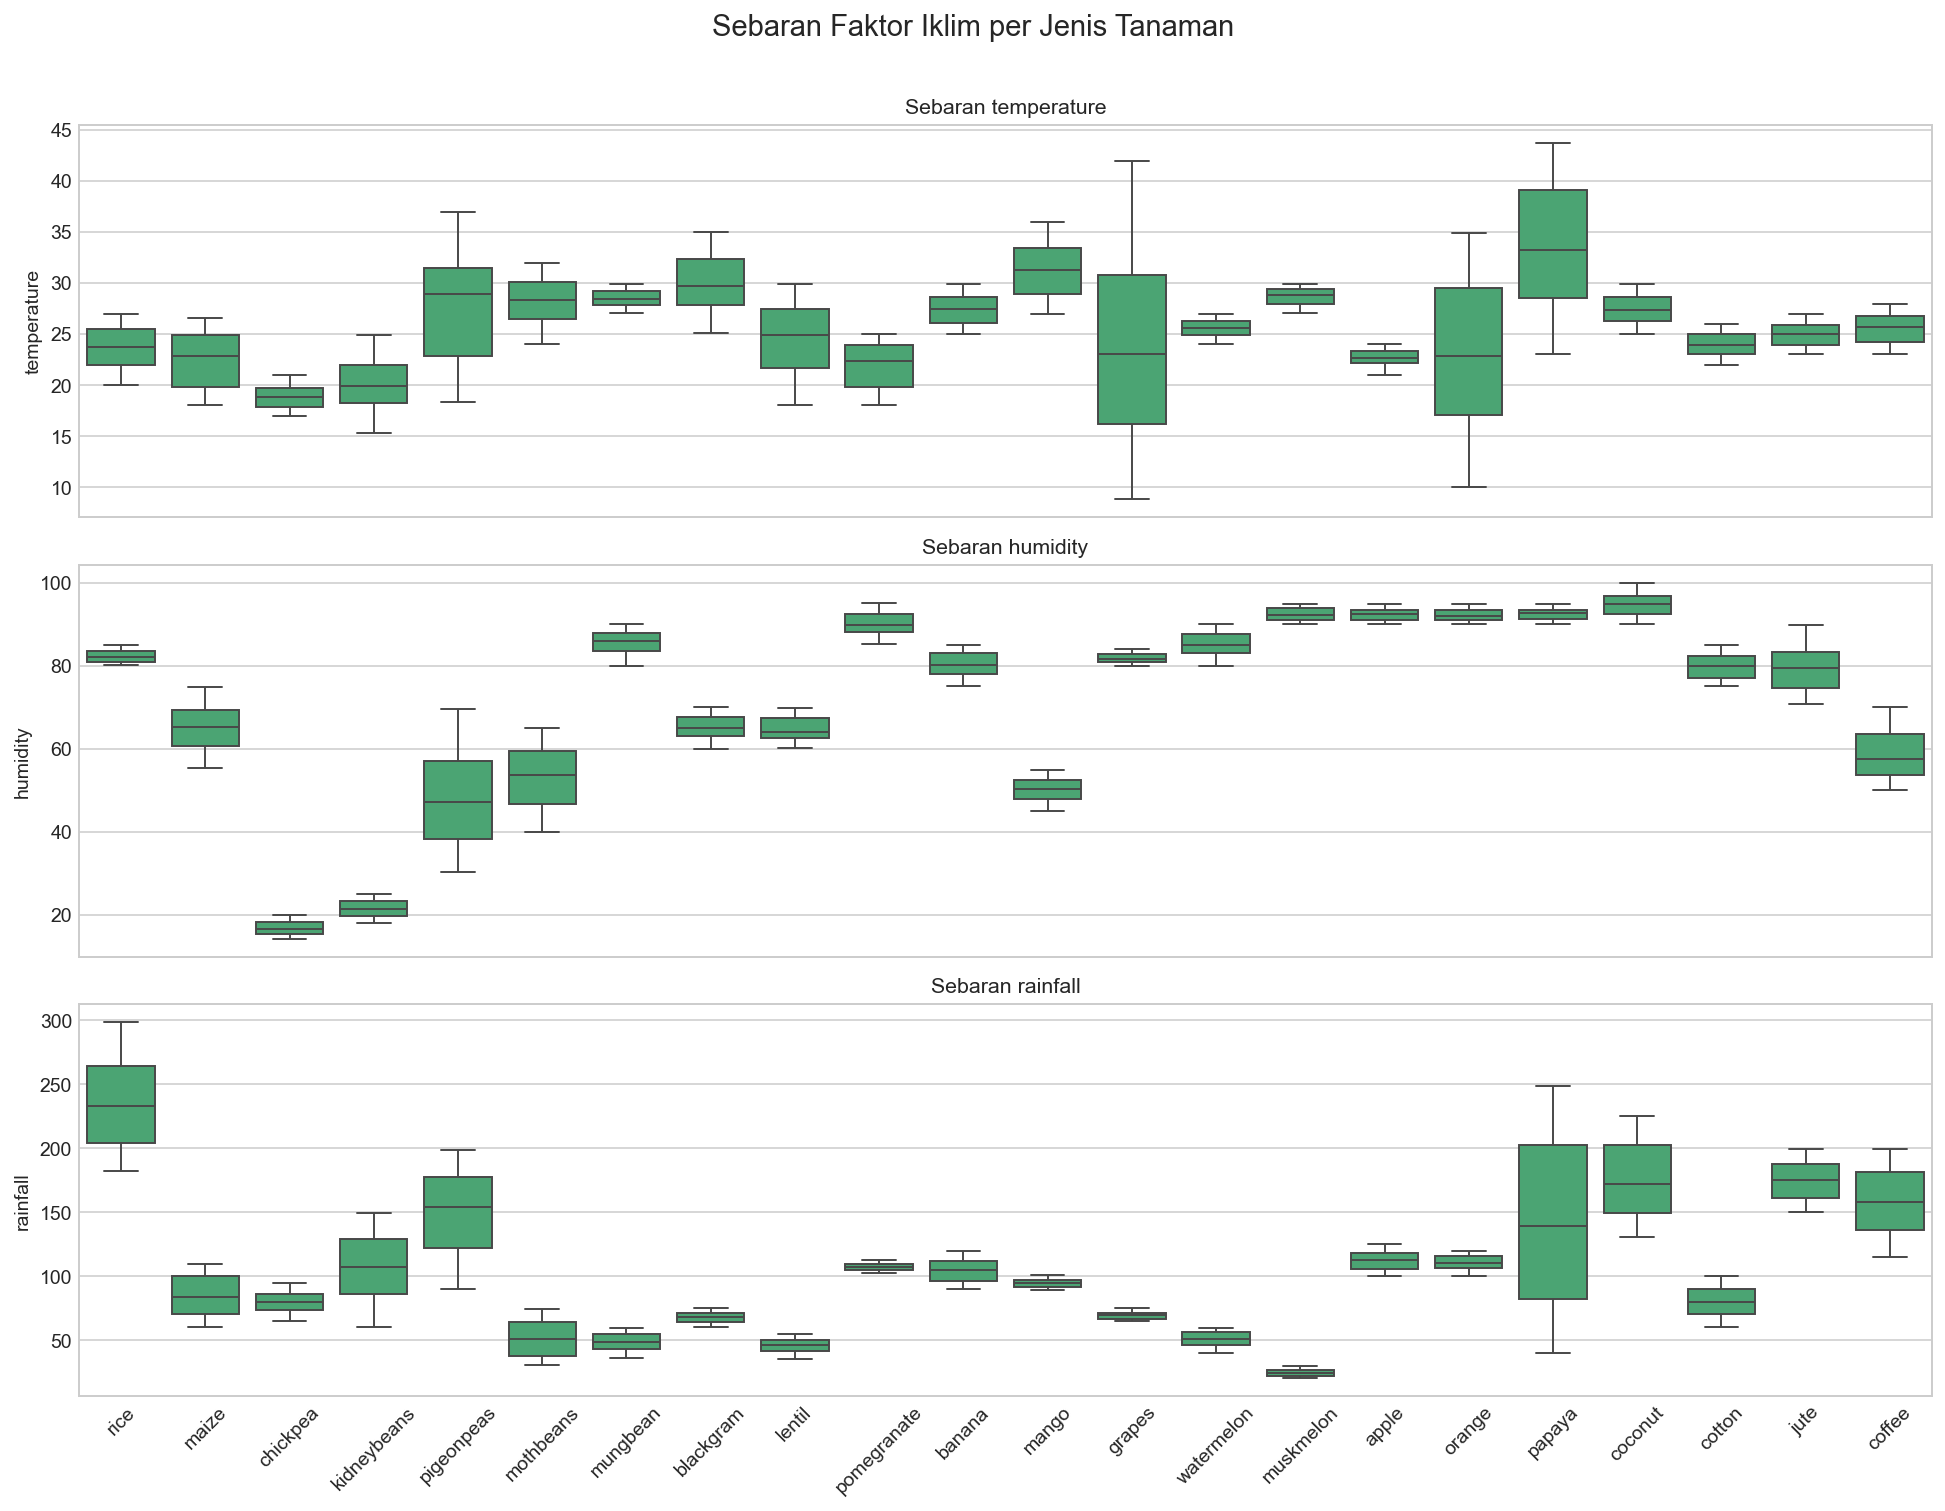

[EDA_PLOT] chart=eda_climate_boxplots.png | saved=../artifacts/plots/eda/eda_climate_boxplots.png


In [8]:
_ = plot_feature_group_boxplots(
    df,
    config,
    features=["temperature", "humidity", "rainfall"],
    title="Sebaran Faktor Iklim per Jenis Tanaman",
    filename="eda_climate_boxplots.png",
)

## **5. Ringkasan Temuan EDA**

1. Dataset terdiri dari 2.200 baris dan 8 kolom tanpa *missing value* maupun duplikat, dengan 22 kelas tanaman yang seimbang (100 sampel per kelas).
2. Fitur `P` dan `K` memiliki korelasi positif sebesar `0.74`, sedangkan fitur iklim dan pH cenderung saling independen.
3. Distribusi `K` dan `P` bersifat multimodal dengan klaster nilai tinggi (`K` sekitar `200`, `P` sekitar `120` hingga `145`) pada kelas `apple` dan `grapes`, sehingga menjadi fitur pembeda yang kuat bagi model klasifikasi.
4. Seluruh grafik EDA tersimpan pada `artifacts/plots/eda/`.